# Product Recommendation with Beta-Bernoulli Thompson Sampling
**Course:** Applied Reinforcement Learning and Optimization (ARLO)

**Problem.** An e-commerce site must decide which product to show each visitor. Each product is an *arm*; showing it and observing a click (1) or no click (0) is a Bernoulli reward with unknown click-through rate (CTR). The goal is to maximise total clicks, which means balancing *exploration* (learning CTRs) against *exploitation* (showing the best product).

**Data.** Open Bandit Dataset (Saito et al., 2021), real logs from ZOZOTOWN, a large Japanese fashion e-commerce platform. We use the logs collected by a **uniform-random** policy, so every product was shown with equal probability and the per-item CTR estimates are unbiased.

**Methods.** Random, ε-greedy, UCB1 and **Beta-Bernoulli Thompson Sampling** (implemented from scratch), evaluated by
1. online simulation in an environment calibrated to the real CTRs (regret analysis), and
2. offline **replay evaluation** on the real logs (Li et al., 2011).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
SEED = 42

## 1. Data loading and exploration

In [2]:
df = pd.read_csv('data/random/all/all.csv', index_col=0)
items = pd.read_csv('data/random/all/item_context.csv', index_col=0)
print('Logged impressions :', len(df))
print('Number of products :', df.item_id.nunique())
print('Positions          :', sorted(df.position.unique()))
print('Overall CTR        : %.4f' % df.click.mean())
print('Logging propensity :', df.propensity_score.unique()[:5])
df[['timestamp','item_id','position','click','propensity_score']].head()

Logged impressions : 10000
Number of products : 80
Positions          : [np.int64(1), np.int64(2), np.int64(3)]
Overall CTR        : 0.0038
Logging propensity : [0.0125]


,timestamp,item_id,position,click,propensity_score
0,2019-11-24 00:00:34.762830+00:00,14,3,0,0.0125
1,2019-11-24 00:00:53.965051+00:00,14,3,0,0.0125
2,2019-11-24 00:00:56.727734+00:00,27,3,0,0.0125
3,2019-11-24 00:02:17.189232+00:00,48,2,0,0.0125
4,2019-11-24 00:03:02.129117+00:00,36,2,0,0.0125


         clicks  shows       ctr
item_id                         
49            3    114  0.026316
53            2    105  0.019048
58            2    112  0.017857
18            2    119  0.016807
36            2    122  0.016393
6             2    131  0.015267
44            2    136  0.014706
57            2    149  0.013423
61            1    104  0.009615
48            1    115  0.008696


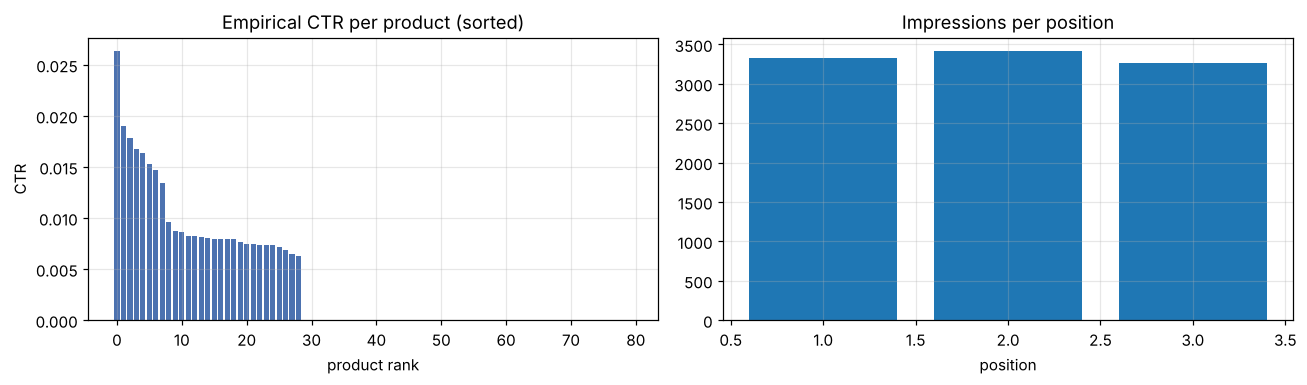

In [3]:
stats = df.groupby('item_id').click.agg(clicks='sum', shows='count', ctr='mean').sort_values('ctr', ascending=False)
print(stats.head(10))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(range(len(stats)), stats.ctr, color='#4C72B0'); ax[0].set(title='Empirical CTR per product (sorted)', xlabel='product rank', ylabel='CTR')
ax[1].bar(*np.unique(df.position, return_counts=True)); ax[1].set(title='Impressions per position', xlabel='position')
plt.tight_layout(); plt.show()

Clicks are rare (CTR ≈ 0.4%) and the gaps between products are small, which makes exploration hard. That is exactly where a principled method such as Thompson Sampling should help.

## 2. Bandit environment
The true click probability of each product is set to its empirical CTR from the uniform-random logs. When a product is shown, the environment returns `click ~ Bernoulli(p_item)`.

In [4]:
class ProductBanditEnv:
    def __init__(self, p, seed=None):
        self.p = np.asarray(p, float); self.K = len(p)
        self.best = self.p.max(); self.rng = np.random.default_rng(seed)
    def step(self, a):
        return int(self.rng.random() < self.p[a])

item_ids = np.sort(df.item_id.unique())
true_ctr = stats.ctr.reindex(item_ids).values
K = len(true_ctr)
print('K =', K, '| best CTR = %.4f (item %d) | mean CTR = %.4f' % (true_ctr.max(), item_ids[true_ctr.argmax()], true_ctr.mean()))

K = 80 | best CTR = 0.0263 (item 49) | mean CTR = 0.0038


## 3. Agents
**Beta-Bernoulli Thompson Sampling.** Each arm *k* gets a Beta(αₖ, βₖ) posterior over its CTR. At every step:
1. sample θₖ ~ Beta(αₖ, βₖ) for every arm,
2. show the product with the largest θₖ,
3. update with the observed click r: αₖ ← αₖ + r, βₖ ← βₖ + (1 − r).

The Beta prior is conjugate to the Bernoulli likelihood, so the posterior stays Beta and each update is O(1). Arms that are uncertain get explored automatically, through the randomness of the posterior samples.

In [5]:
class RandomAgent:
    name = 'Random'
    def __init__(self, K, rng): self.K, self.rng = K, rng
    def select(self): return self.rng.integers(self.K)
    def update(self, a, r): pass

class EpsilonGreedy:
    def __init__(self, K, rng, eps=0.1):
        self.K, self.rng, self.eps = K, rng, eps; self.n = np.zeros(K); self.s = np.zeros(K)
        self.name = f'ε-greedy (ε={eps})'
    def select(self):
        if self.rng.random() < self.eps: return self.rng.integers(self.K)
        q = np.divide(self.s, self.n, out=np.full(self.K, np.inf), where=self.n > 0)
        return self.rng.choice(np.flatnonzero(q == q.max()))
    def update(self, a, r): self.n[a] += 1; self.s[a] += r

class UCB1:
    name = 'UCB1'
    def __init__(self, K, rng): self.K, self.rng = K, rng; self.n = np.zeros(K); self.s = np.zeros(K); self.t = 0
    def select(self):
        self.t += 1
        if (self.n == 0).any(): return int(np.flatnonzero(self.n == 0)[0])
        u = self.s / self.n + np.sqrt(2 * np.log(self.t) / self.n)
        return int(u.argmax())
    def update(self, a, r): self.n[a] += 1; self.s[a] += r

class BetaBernoulliTS:
    def __init__(self, K, rng, a0=1.0, b0=1.0):
        self.K, self.rng = K, rng; self.alpha = np.full(K, a0); self.beta = np.full(K, b0)
        self.name = 'TS (uniform prior)' if (a0, b0) == (1, 1) else f'TS Beta({a0:g},{b0:g})'
    def select(self): return int(self.rng.beta(self.alpha, self.beta).argmax())
    def update(self, a, r): self.alpha[a] += r; self.beta[a] += 1 - r

## 4. Online simulation: regret and CTR

In [6]:
def run(make_agent, T, n_runs, p):
    regret = np.zeros((n_runs, T)); clicks = np.zeros((n_runs, T)); pulls = np.zeros((n_runs, len(p))); agents = []
    for i in range(n_runs):
        env = ProductBanditEnv(p, seed=SEED + i); agent = make_agent(np.random.default_rng(1000 + i))
        for t in range(T):
            a = agent.select(); r = env.step(a); agent.update(a, r)
            regret[i, t] = env.best - p[a]; clicks[i, t] = r; pulls[i, a] += 1
        agents.append(agent)
    return dict(name=agent.name, cum_regret=regret.cumsum(1), clicks=clicks, pulls=pulls, agents=agents)

T, N_RUNS = 100_000, 8
BASE = df.click.mean()   # empirical-Bayes prior: mean = base CTR, strength = 1/BASE pseudo-shows
makers = [lambda g: RandomAgent(K, g), lambda g: EpsilonGreedy(K, g, 0.1),
          lambda g: UCB1(K, g), lambda g: BetaBernoulliTS(K, g),
          lambda g: BetaBernoulliTS(K, g, 1, round(1 / BASE) - 1)]
makers_named = None
results = [run(m, T, N_RUNS, true_ctr) for m in makers]
results[4]['name'] = 'TS (base-rate prior)'
for r in results: print(f"{r['name']:<22} final regret = {r['cum_regret'][:, -1].mean():7.1f}")

Random                 final regret =  2254.6
ε-greedy (ε=0.1)       final regret =   799.6
UCB1                   final regret =  2200.3
TS (uniform prior)     final regret =   739.1
TS (base-rate prior)   final regret =   381.1


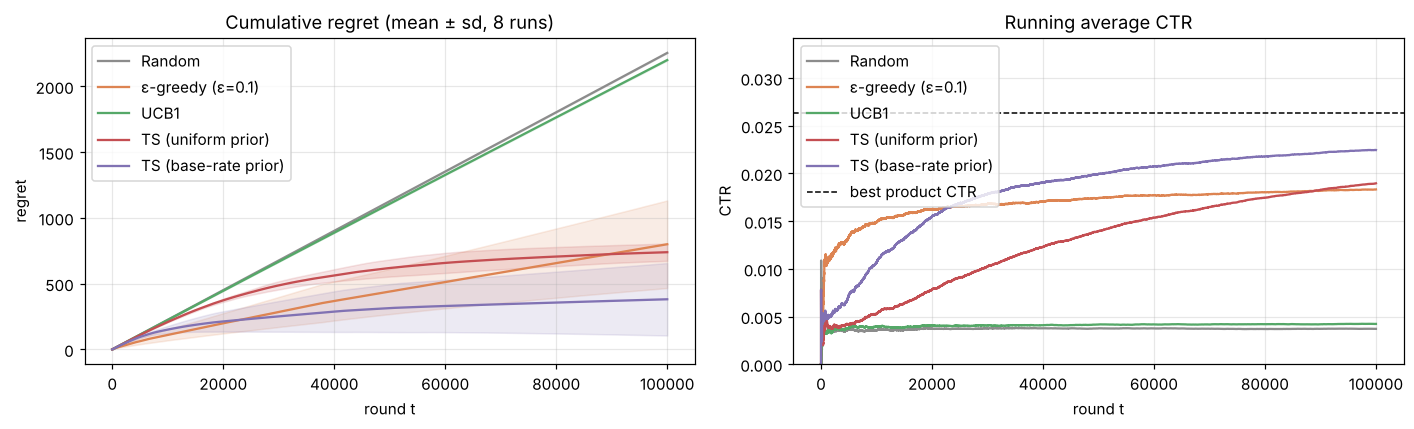

In [7]:
cols = ['#8c8c8c', '#DD8452', '#55A868', '#C44E52', '#8172B3']
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r, c in zip(results, cols):
    m, s = r['cum_regret'].mean(0), r['cum_regret'].std(0)
    ax[0].plot(m, label=r['name'], color=c); ax[0].fill_between(range(T), m - s, m + s, color=c, alpha=.15)
    ctr_t = r['clicks'].mean(0).cumsum() / np.arange(1, T + 1)
    ax[1].plot(ctr_t, label=r['name'], color=c)
ax[1].axhline(true_ctr.max(), ls='--', c='k', lw=1, label='best product CTR')
ax[0].set(title=f'Cumulative regret (mean ± sd, {N_RUNS} runs)', xlabel='round t', ylabel='regret')
ax[1].set(title='Running average CTR', xlabel='round t', ylabel='CTR', ylim=(0, true_ctr.max() * 1.3))
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

### What Thompson Sampling learned

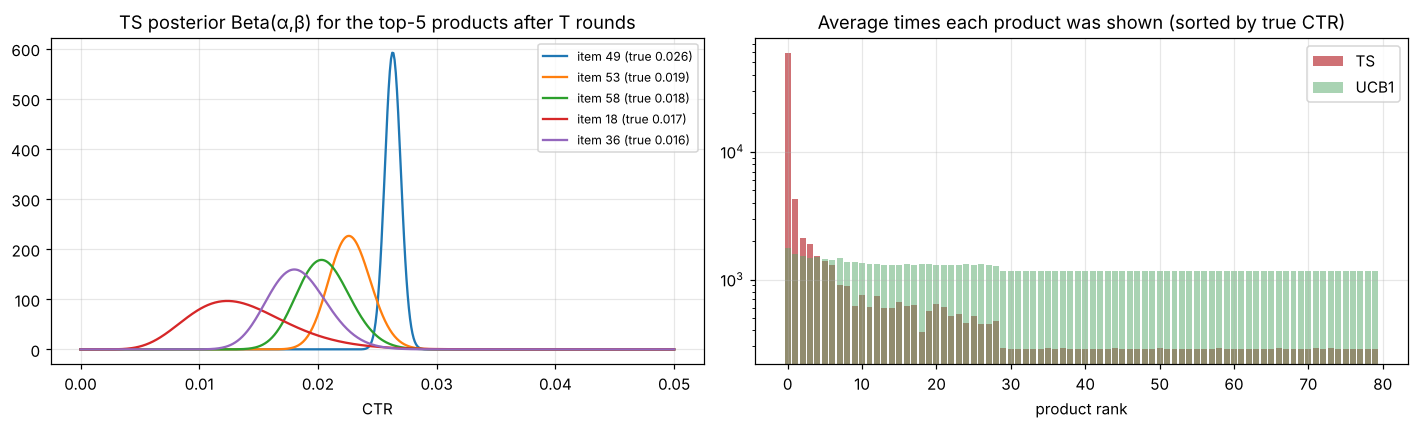

In [8]:
from scipy.stats import beta as beta_dist
ts = results[3]; agent = ts['agents'][0]
top = np.argsort(true_ctr)[::-1][:5]; x = np.linspace(0, 0.05, 500)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in top:
    ax[0].plot(x, beta_dist.pdf(x, agent.alpha[k], agent.beta[k]), label=f'item {item_ids[k]} (true {true_ctr[k]:.3f})')
ax[0].set(title='TS posterior Beta(α,β) for the top-5 products after T rounds', xlabel='CTR'); ax[0].legend(fontsize=8)
order = np.argsort(true_ctr)[::-1]
ax[1].bar(range(K), ts['pulls'].mean(0)[order], color='#C44E52', alpha=.8, label='TS')
ax[1].bar(range(K), results[2]['pulls'].mean(0)[order], color='#55A868', alpha=.5, label='UCB1')
ax[1].set(title='Average times each product was shown (sorted by true CTR)', xlabel='product rank', yscale='log'); ax[1].legend()
plt.tight_layout(); plt.show()

### Effect of the prior

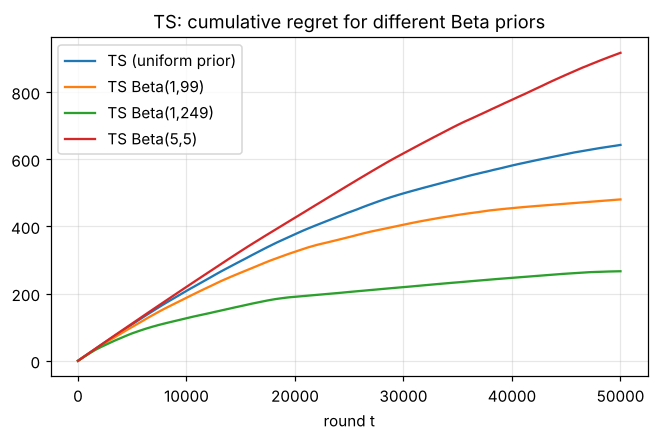

TS (uniform prior)     final regret =   642.6
TS Beta(1,99)          final regret =   480.3
TS Beta(1,249)         final regret =   266.6
TS Beta(5,5)           final regret =   916.7


In [9]:
prior_makers = [lambda g: BetaBernoulliTS(K, g, 1, 1), lambda g: BetaBernoulliTS(K, g, 1, 99),
                lambda g: BetaBernoulliTS(K, g, 1, 249), lambda g: BetaBernoulliTS(K, g, 5, 5)]
prior_res = [run(m, 50_000, 5, true_ctr) for m in prior_makers]
plt.figure(figsize=(7, 4))
for r in prior_res: plt.plot(r['cum_regret'].mean(0), label=r['name'])
plt.title('TS: cumulative regret for different Beta priors'); plt.xlabel('round t'); plt.legend(); plt.show()
for r in prior_res: print(f"{r['name']:<22} final regret = {r['cum_regret'][:, -1].mean():7.1f}")

Beta(1, 249) puts the prior mean at 0.4%, close to the real base CTR, so the agent stops over-exploring arms it has barely tried. Beta(5, 5) is badly mis-specified (prior mean 50%) and wastes many rounds before it unlearns that belief.

## 5. Offline replay evaluation on the real logs (Li et al., 2011)
Because the logging policy was uniform-random, replay gives an unbiased estimate of a policy's CTR. Walk through the log in order; whenever the policy picks the same product that was actually shown, record that real click and update the policy. Other events are skipped. With K = 80, only about 1/80 of events match, so we average over many random orderings of the log.

In [10]:
def replay(make_agent, logs_a, logs_r, n_shuffles=200):
    ctrs, matched = [], []
    for i in range(n_shuffles):
        rng = np.random.default_rng(i); idx = rng.permutation(len(logs_a)); agent = make_agent(np.random.default_rng(10_000 + i))
        clicks = n = 0
        for j in idx:
            a = agent.select()
            if a == logs_a[j]:
                r = logs_r[j]; agent.update(a, r); clicks += r; n += 1
        ctrs.append(clicks / max(n, 1)); matched.append(n)
    return np.array(ctrs), np.array(matched)

arm_index = {it: k for k, it in enumerate(item_ids)}
la = df.item_id.map(arm_index).values; lr = df.click.values
rows = []
for m, r_name in zip(makers, [r['name'] for r in results]):
    c, n = replay(m, la, lr)
    rows.append((r_name, c.mean(), c.std() / np.sqrt(len(c)), n.mean()))
rep = pd.DataFrame(rows, columns=['policy', 'replay CTR', 'std error', 'avg matched events'])
rep['lift vs random'] = rep['replay CTR'] / rep.loc[0, 'replay CTR'] - 1
rep.style.format({'replay CTR': '{:.4f}', 'std error': '{:.4f}', 'avg matched events': '{:.0f}', 'lift vs random': '{:+.1%}'})

,policy,replay CTR,std error,avg matched events,lift vs random
0,Random,0.0047,0.0004,126,+0.0%
1,ε-greedy (ε=0.1),0.0046,0.0004,124,-2.3%
2,UCB1,0.0036,0.0004,126,-24.0%
3,TS (uniform prior),0.0041,0.0004,124,-13.8%
4,TS (base-rate prior),0.0040,0.0004,126,-14.2%


## 6. Summary

In [11]:
summary = pd.DataFrame({
    'policy': [r['name'] for r in results],
    'final cum. regret': [r['cum_regret'][:, -1].mean() for r in results],
    'simulated CTR': [r['clicks'].mean() for r in results],
    '% shows of top-5 items': [r['pulls'][:, np.argsort(true_ctr)[-5:]].sum(1).mean() / T * 100 for r in results]})
summary['replay CTR (real logs)'] = rep['replay CTR'].values
summary.round(4)

,policy,final cum. regret,simulated CTR,% shows of top-5 items,replay CTR (real logs)
0,Random,2254.5779,0.0037,6.2265,0.0047
1,ε-greedy (ε=0.1),799.6183,0.0183,84.1948,0.0046
2,UCB1,2200.3457,0.0042,7.8499,0.0036
3,TS (uniform prior),739.0504,0.0190,69.3318,0.0041
4,TS (base-rate prior),381.1261,0.0225,88.8982,0.0040


**Takeaways (simulation, T = 100k, 8 runs)**
- **Thompson Sampling has the lowest regret of every method.** With a uniform Beta(1,1) prior it edges out ε-greedy (≈740 vs ≈800), and the gap keeps widening: TS regret grows roughly logarithmically, while ε-greedy's grows linearly because it keeps exploring 10% of the time forever.
- **The prior matters a lot when rewards are sparse.** Beta(1,1) starts every product at an assumed 50% CTR, so TS has to see many no-clicks before it lets go of an arm. Setting the prior mean to the real base CTR (Beta(1, 262), an empirical-Bayes choice) **roughly halves regret** (≈380) and shows the top-5 products about 89% of the time.
- **UCB1 is barely better than random here.** Its √(2 ln t / n) bonus is about 0.1 even after hundreds of pulls, which dwarfs CTR gaps of about 0.01. Fixed confidence bounds do not suit very low-CTR problems; a KL-UCB-style bound would be needed.
- **Replay on the real logs gives only about 125 matched events per pass**, so every policy's replay CTR lies within noise of the others. Separating them reliably needs the full Open Bandit Dataset (~26M events) and is left as future work.

**Limitations and next steps.** Plain TS ignores who the user is and treats every visitor alike. The next step is **contextual** bandits (Linear TS / LinUCB) using the `user_feature_*` and `user-item_affinity_*` columns, followed by sequential RL (Q-learning / policy gradient) for session-level recommendation.

**References**
1. Chapelle, O. & Li, L. (2011). An Empirical Evaluation of Thompson Sampling. *NeurIPS*.
2. Agrawal, S. & Goyal, N. (2012). Analysis of Thompson Sampling for the Multi-armed Bandit Problem. *COLT*.
3. Li, L., Chu, W., Langford, J., Wang, X. (2011). Unbiased Offline Evaluation of Contextual-bandit-based News Article Recommendation Algorithms. *WSDM*.
4. Saito, Y., Aihara, S., Matsutani, M., Narita, Y. (2021). Open Bandit Dataset and Pipeline: Towards Realistic and Reproducible Off-Policy Evaluation. *NeurIPS Datasets & Benchmarks*.
5. Russo, D., Van Roy, B., Kazerouni, A., Osband, I., Wen, Z. (2018). A Tutorial on Thompson Sampling. *Foundations and Trends in ML*.